<a href="https://colab.research.google.com/github/MaheyshRamesh/DataEngineering/blob/main/Copy_of_Assignment1_Data_Profiling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1: Data Profiling (EDA) Report
## Online Retail II: diagnosing and fixing data quality problems

| Member | Name | Matric number | Responsibility |
|---|---|---|---|
| Member 1 | Maheysh A/L Ramesh | A211881 | Dataset, setup, size/columns/dtypes, duplicates, data types, GitHub repo |
| Member 2 | Shukri Aizat bin Shuazrin | A212202 | _TODO_ |
| Member 3 | Ahmad Nazmi bin Bastian Affendy | A212353 | _TODO_ |
| Member 4 | Danish Irfan bin Hakimi | A213696 | _TODO_ |


**Contents:** 1 Scenario · 2 Data source · 3 Profiling and issue handling (3.1 load, 3.2 data types, 3.3 duplicates, 3.4 missing values, 3.5 outliers, 3.6 other issues) · 4 Diagnostic charts · 5 PII and bias risks · 6 Conclusion

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MaheyshRamesh/DataEngineering/blob/main/Assignment1_Data_Profiling.ipynb)

> **How to run (Google Colab):** click the badge above (or upload this notebook to Colab), then choose *Runtime > Run all*. No installation or manual download is needed.
> **How to run (locally):** see `README.md`; install `requirements.txt`, then *Kernel > Restart & Run All*.
> The dataset is downloaded automatically on the first run (the Excel file is about 44 MB, so the first load takes a few minutes). Later runs in the same session use a cache.

In [ ]:
# Setup: install anything missing. This is a no-op on Google Colab, which already has these packages.
import importlib.util
import subprocess
import sys

REQUIRED = {"pandas": "pandas", "openpyxl": "openpyxl", "pyarrow": "pyarrow", "matplotlib": "matplotlib"}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already installed.")

IN_COLAB = "google.colab" in sys.modules
print("Running on Google Colab" if IN_COLAB else "Running locally")

All required packages are already installed.
Running on Google Colab


In [ ]:
from pathlib import Path
import shutil
import time
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.dpi"] = 110

DATA_URL = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"

ROOT = Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
INTERIM_DIR = ROOT / "data" / "interim"
PROCESSED_DIR = ROOT / "data" / "processed"
for d in (RAW_DIR, INTERIM_DIR, PROCESSED_DIR):
    d.mkdir(parents=True, exist_ok=True)

ZIP_PATH = RAW_DIR / "online_retail_ii.zip"
XLSX_PATH = RAW_DIR / "online_retail_II.xlsx"
RAW_CACHE = INTERIM_DIR / "raw_both_sheets.pkl"
print("Working directory:", ROOT)

Working directory: /content


## 1. Scenario

An online gift retailer wants to use its sales and customer data to improve business performance: it needs to identify its best-selling products, understand how customers buy, and predict future sales. All three analyses rely on clean transaction records, so before any modelling we must profile the data and repair its quality problems. Our questions are: (1) which products sell best by units and by revenue, (2) how do customers differ in how often and how much they buy, and (3) can weekly sales be forecast from the history?

**Why this dataset fits the brief** (real, messy, and has risks to discuss):
- It is a real transaction log, not a synthetic or pre-cleaned file, and it was never prepared for analysis.
- It contains missing values (customer IDs, descriptions), outliers (very large quantities and prices), duplicates, wrong or mixed data types, invalid values (negative quantities and prices), non-product rows, and cancellations.
- It has an identifier field (`Customer ID`) and a strong sampling bias (a single UK retailer, mostly UK buyers and many wholesalers), so PII and bias can be discussed.
- It spans two years (Dec 2009 to Dec 2011), enough to look at seasonality for the forecasting question.

## 2. Data source

| Item | Detail |
|---|---|
| Dataset | **Online Retail II** (UCI Machine Learning Repository, dataset id 502) |
| Page | https://archive.ics.uci.edu/dataset/502/online+retail+ii |
| Direct download | https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip |
| DOI | https://doi.org/10.24432/C5CG6D |
| Licence | Creative Commons Attribution 4.0 International (CC BY 4.0), as stated on the UCI page |
| Content | All transactions of a UK-based, registered non-store online retailer (mainly unique all-occasion gifts, many customers are wholesalers), 01/12/2009 to 09/12/2011 |
| How we obtained it | Downloaded programmatically from the UCI static URL above by the cell below. It is a public open-data download, so no scraping, login or API key is involved. The zip contains one Excel workbook, `online_retail_II.xlsx`, with two sheets (one per trading year). |

_Citation (as given on the UCI page):_ Chen, D. (2012). *Online Retail II* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D.

In [ ]:
def download_dataset():
    """Download and extract the workbook once; skip if it is already on disk."""
    if XLSX_PATH.exists():
        print(f"Already downloaded: {XLSX_PATH.name} ({XLSX_PATH.stat().st_size / 1e6:.1f} MB)")
        return

    part_path = ZIP_PATH.with_suffix(".part")
    for attempt in range(1, 5):  # retry a few times: public servers can be slow or drop connections
        try:
            print(f"Downloading from UCI (attempt {attempt}) ...")
            request = urllib.request.Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0 (data-engineering-assignment)"})
            with urllib.request.urlopen(request, timeout=60) as response, open(part_path, "wb") as out:
                shutil.copyfileobj(response, out, length=1 << 20)  # stream to disk in 1 MB chunks
            if not zipfile.is_zipfile(part_path):
                raise ValueError("Downloaded file is not a valid zip")
            part_path.replace(ZIP_PATH)
            break
        except Exception as exc:
            print(f"  failed: {type(exc).__name__}: {exc}")
            if attempt == 4:
                raise RuntimeError(
                    "Could not download the dataset. Download the zip manually from "
                    f"{DATA_URL} and place online_retail_II.xlsx in {RAW_DIR}"
                ) from exc
            time.sleep(5 * attempt)

    with zipfile.ZipFile(ZIP_PATH) as archive:
        archive.extract("online_retail_II.xlsx", RAW_DIR)
    print(f"Saved {XLSX_PATH.name} ({XLSX_PATH.stat().st_size / 1e6:.1f} MB)")

download_dataset()

Saved online_retail_II.xlsx (45.6 MB)


## 3. Data profiling and issue handling

### 3.1 Load the data and inspect size, columns and data types _(Member 1)_

The workbook has **two sheets** (one per trading year). We read both with the default pandas types, add a `source_sheet` column that records which sheet each row came from (this is our own lineage column, not part of the source data), and stack them. We keep this untouched copy as `raw` so every later fix can be compared against it. Reading Excel is slow, so the raw frame is cached as a pickle for later runs.

In [ ]:
if RAW_CACHE.exists():
    raw = pd.read_pickle(RAW_CACHE)
    print("Loaded cached raw data")
else:
    sheets = pd.read_excel(XLSX_PATH, sheet_name=None)  # dict: sheet name -> DataFrame
    frames = []
    for name, frame in sheets.items():
        frame = frame.copy()
        frame["source_sheet"] = name
        frames.append(frame)
    raw = pd.concat(frames, ignore_index=True)
    raw.to_pickle(RAW_CACHE)
    print("Read Excel and cached raw data")

sheet_names = list(raw["source_sheet"].unique())
print(f"\nRows: {raw.shape[0]:,}   Columns: {raw.shape[1]}   Memory: {raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
print("\nRows per sheet:")
print(raw.groupby("source_sheet").size().to_string())

Read Excel and cached raw data

Rows: 1,067,371   Columns: 9   Memory: 328 MB

Rows per sheet:
source_sheet
Year 2009-2010    525461
Year 2010-2011    541910


In [ ]:
summary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing": raw.isna().sum(),
    "n_unique": raw.nunique(dropna=True),
})
display(summary)
display(raw.head())

,dtype,non_null,missing,n_unique
Invoice,object,1067371,0,53628
StockCode,object,1067371,0,5305
Description,object,1062989,4382,5698
Quantity,int64,1067371,0,1057
InvoiceDate,datetime64[ns],1067371,0,47635
Price,float64,1067371,0,2807
Customer ID,float64,824364,243007,5942
Country,object,1067371,0,43
source_sheet,object,1067371,0,2


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,source_sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,Year 2009-2010


### 3.2 Incorrect data types: audit and fix _(Member 1)_

`DataFrame.dtypes` only reports `object` for text-like columns, which hides the real problem. So we look at the **Python type of each value**, and check whether each column's type matches what the column means.

In [ ]:
for col in ["Invoice", "StockCode", "Description"]:
    print(f"--- {col}: Python type of each value ---")
    print(raw[col].map(lambda v: type(v).__name__).value_counts(dropna=False).to_string())
    print()

cid = raw["Customer ID"].dropna()
print("Customer ID dtype:", raw["Customer ID"].dtype, "| all non-null values are whole numbers:", bool((cid % 1 == 0).all()))
print("InvoiceDate dtype:", raw["InvoiceDate"].dtype, "| range:", raw["InvoiceDate"].min(), "->", raw["InvoiceDate"].max())

prefix = raw["Invoice"].astype(str).str.extract(r"^([A-Za-z]*)")[0].replace("", "(digits only)")
print("\nInvoice prefixes (letters before the number):")
print(prefix.value_counts().to_string())

--- Invoice: Python type of each value ---
Invoice
int    1047871
str      19500

--- StockCode: Python type of each value ---
StockCode
int    932385
str    134986

--- Description: Python type of each value ---
Description
str      1062985
float       4382
int            4

Customer ID dtype: float64 | all non-null values are whole numbers: True
InvoiceDate dtype: datetime64[ns] | range: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00

Invoice prefixes (letters before the number):
0
(digits only)    1047871
C                  19494
A                      6


**Findings and decisions**

| Column | Problem found | Why it is wrong | Fix and reason |
|---|---|---|---|
| `Invoice` | Mixed Python types: Excel stored plain numbers as integers but numbers with a letter prefix (`C` for cancellations, `A` for adjustments) as text | An identifier is a label, not a quantity: you never add or average invoice numbers, and mixed types break joins, sorting and `groupby` | Convert to string. We keep the prefix, because the `C` prefix is the only marker for cancellations. |
| `StockCode` | Mixed integers and text (e.g. `85123A`, `POST`, `M`) | Same reason: product codes are identifiers | Convert to string |
| `Description` | Free text, but missing values are stored as float `NaN` and a few entries were read as integers (see the type counts above) | A text column should hold only text or an explicit missing marker | Convert to pandas `string` dtype, so numbers become text and missing values become `<NA>` |
| `Customer ID` | `float64` | Pandas stores it as float only because some values are missing (NaN), but an ID is a label. Float would also print as `13085.0` and could lose digits in joins | Convert float to nullable integer, then to string, so missing IDs stay missing instead of becoming a fake number |
| `Country` | `object`, few repeated labels | Low-cardinality label, wasteful as free text | Convert to `category` |
| `InvoiceDate` | Already `datetime64` | Correct, no fix needed | None |
| `Quantity`, `Price` | `int64` and `float64` | Correct for numeric measures | None (their invalid values are handled in 3.5 and 3.6) |

We also rename columns to `snake_case` (`Customer ID` has a space, and the names differ from the first UCI file), and add a boolean `is_cancellation` flag derived from the `C` prefix, so the information is not buried in a string.

In [ ]:
COLUMN_NAMES = {
    "Invoice": "invoice", "StockCode": "stock_code", "Description": "description",
    "Quantity": "quantity", "InvoiceDate": "invoice_date", "Price": "price",
    "Customer ID": "customer_id", "Country": "country",
}
ORIG_COLS = list(COLUMN_NAMES.values())  # the 8 source columns (excludes our own source_sheet)

df = raw.rename(columns=COLUMN_NAMES).copy()
dtypes_before = df.dtypes.astype(str)

for col in ["invoice", "stock_code", "description"]:
    df[col] = df[col].astype("string")

# Customer ID: float -> nullable integer -> string (missing stays missing)
assert (df["customer_id"].dropna() % 1 == 0).all(), "Customer IDs are not all whole numbers"
df["customer_id"] = df["customer_id"].astype("Int64").astype("string")

df["country"] = df["country"].astype("category")
df["is_cancellation"] = df["invoice"].str.startswith("C").astype(bool)

pd.DataFrame({"before": dtypes_before, "after": df.dtypes.astype(str)}).loc[list(df.columns)]

,before,after
invoice,object,string
stock_code,object,string
description,object,string
quantity,int64,int64
invoice_date,datetime64[ns],datetime64[ns]
price,float64,float64
customer_id,float64,string
country,object,category
source_sheet,object,object
is_cancellation,NaN,bool


In [ ]:
# Proof that the conversion left consistent types
for col in ["invoice", "stock_code", "description", "customer_id"]:
    print(col, "->", df[col].map(lambda v: type(v).__name__).value_counts(dropna=False).to_dict())
print("\nExample IDs:", df["customer_id"].dropna().head(3).tolist(), "| missing IDs preserved:", int(df["customer_id"].isna().sum()))

invoice -> {'str': 1067371}
stock_code -> {'str': 1067371}
description -> {'str': 1062989, 'NAType': 4382}
customer_id -> {'str': 824364, 'NAType': 243007}

Example IDs: ['13085', '13085', '13085'] | missing IDs preserved: 243007


### 3.3 Duplicates: identify and fix _(Member 1)_

**What counts as a duplicate here?** The data has no unique row ID, so a duplicate is a row that is identical in **all eight source columns** (invoice, stock code, description, quantity, timestamp to the minute, price, customer, country). We look at it in three steps, from clear-cut to ambiguous:

1. **Exact duplicates**, split into repeats *inside one sheet* and records that appear in *both sheets*.
2. **Hidden duplicates**, which only become exact after fixing trivial formatting (extra spaces, upper/lower case).
3. **Near-duplicates**, rows that match on everything except the description text.

In [ ]:
total_dups = int(df.duplicated(subset=ORIG_COLS).sum())
within = {s: int(g.duplicated(subset=ORIG_COLS).sum()) for s, g in df.groupby("source_sheet", observed=True)}
# distinct records that exist in both sheets = total duplicates minus repeats that happen inside a single sheet
cross_sheet = total_dups - sum(within.values())

dup_breakdown = pd.Series({**{f"repeated inside '{s}'": n for s, n in within.items()},
                           "record present in both sheets": cross_sheet})
print(f"Exact duplicate rows (extra copies): {total_dups:,}  ({total_dups / len(df):.2%} of all rows)\n")
print(dup_breakdown.to_string())

s1, s2 = sheet_names[0], sheet_names[1]
overlap_start = df.loc[df["source_sheet"] == s2, "invoice_date"].min()
overlap_end = df.loc[df["source_sheet"] == s1, "invoice_date"].max()
print(f"\nSheet '{s1}' ends at   {overlap_end}")
print(f"Sheet '{s2}' starts at {overlap_start}")
print("The two sheets overlap in time" if overlap_start < overlap_end else "The two sheets do not overlap in time")

Exact duplicate rows (extra copies): 34,335  (3.22% of all rows)

repeated inside 'Year 2009-2010'     6865
repeated inside 'Year 2010-2011'     5268
record present in both sheets       22202

Sheet 'Year 2009-2010' ends at   2010-12-09 20:01:00
Sheet 'Year 2010-2011' starts at 2010-12-01 08:26:00
The two sheets overlap in time


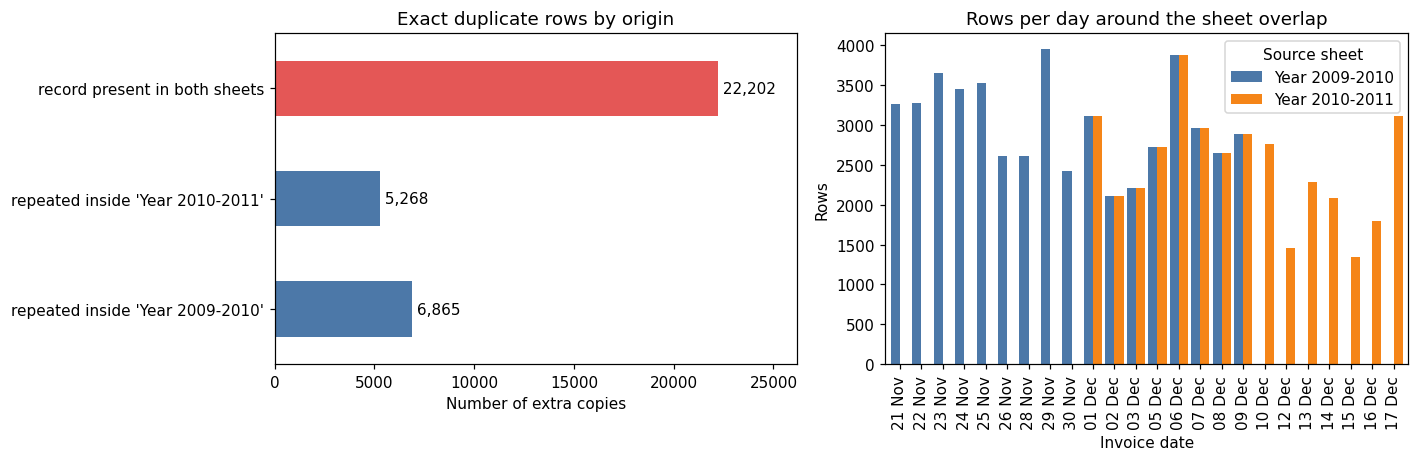

In [ ]:
# Diagnostic chart 1: where do the duplicates come from?
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

dup_breakdown.plot(kind="barh", ax=axes[0], color=["#4C78A8", "#4C78A8", "#E45756"])
axes[0].set_title("Exact duplicate rows by origin")
axes[0].set_xlabel("Number of extra copies")
for i, v in enumerate(dup_breakdown.values):
    axes[0].text(v, i, f" {v:,}", va="center")
axes[0].set_xlim(0, dup_breakdown.max() * 1.18)

lo, hi = overlap_start.normalize() - pd.DateOffset(days=10), overlap_end.normalize() + pd.DateOffset(days=10)
window = df[(df["invoice_date"] >= lo) & (df["invoice_date"] < hi)]
daily = (window.groupby([window["invoice_date"].dt.normalize(), "source_sheet"], observed=True)
               .size().unstack(fill_value=0))
daily.plot(kind="bar", ax=axes[1], width=0.85, color=["#4C78A8", "#F58518"])
axes[1].set_xticklabels([d.strftime("%d %b") for d in daily.index], rotation=90)
axes[1].set_title("Rows per day around the sheet overlap")
axes[1].set_xlabel("Invoice date")
axes[1].set_ylabel("Rows")
axes[1].legend(title="Source sheet")

plt.tight_layout()
plt.show()

In [ ]:
# What do exact duplicates look like? (a few examples, grouped so copies sit together)
dup_rows = df[df.duplicated(subset=ORIG_COLS, keep=False)].sort_values(["invoice", "stock_code", "invoice_date"])
display(dup_rows[ORIG_COLS + ["source_sheet"]].head(8))

print("Invoices containing at least one exact-duplicate line:", dup_rows["invoice"].nunique())

,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,source_sheet
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329,United Kingdom,Year 2009-2010
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329,United Kingdom,Year 2009-2010
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010


Invoices containing at least one exact-duplicate line: 5391


**Decision for exact duplicates: remove all extra copies (keep the first occurrence).**

- *Cross-sheet records* are clearly an artefact of how the workbook was split: the first sheet runs a few days into December 2010 and the second sheet starts at 1 December 2010, so those days appear twice. Keeping them would **double-count sales** for those days, which directly distorts the best-seller ranking and the weekly forecast.
- *Repeats inside one sheet* are less certain. A shop can legitimately scan the same product twice, and no row ID lets us prove otherwise. However, rows that match on invoice, product, quantity, price, customer **and the same minute** are far more likely to be accidental double entries than genuine separate lines, and a genuine repeat would normally appear as one line with a larger quantity. We therefore remove them as well, and **measure the revenue impact below** so the effect of this judgement is visible. This remains a stated limitation.

In [ ]:
# Step 2: hidden duplicates. Normalise trivial formatting differences, then recount.
df["stock_code"] = df["stock_code"].str.strip().str.upper()
df["description"] = df["description"].str.strip().str.replace(r"\s+", " ", regex=True)

total_dups_after_norm = int(df.duplicated(subset=ORIG_COLS).sum())
print(f"Exact duplicates before text normalisation: {total_dups:,}")
print(f"Exact duplicates after  text normalisation: {total_dups_after_norm:,}")
print(f"Hidden duplicates revealed by normalisation: {total_dups_after_norm - total_dups:,}")

raw_desc = raw["Description"].dropna().astype(str)
raw_codes = raw["StockCode"].astype(str)
print(f"\nDescriptions with leading/trailing spaces in the raw data: {int((raw_desc != raw_desc.str.strip()).sum()):,}")
print(f"Distinct stock codes lost by trimming/upper-casing (same product written two ways): {raw_codes.nunique() - raw_codes.str.strip().str.upper().nunique():,}")

Exact duplicates before text normalisation: 34,335
Exact duplicates after  text normalisation: 34,335
Hidden duplicates revealed by normalisation: 0

Descriptions with leading/trailing spaces in the raw data: 213,035
Distinct stock codes lost by trimming/upper-casing (same product written two ways): 174


Text normalisation (strip spaces, collapse repeated spaces, upper-case stock codes) is safe here: `85123a` and `85123A` are the same product, and padded spaces carry no meaning. The recount above shows whether this exposes any further exact duplicates.

In [ ]:
# Step 3: near-duplicates = identical on everything except the description text.
# Evaluated after exact duplicates are removed, so we only look at what is left.
deduped = df.drop_duplicates(subset=ORIG_COLS, keep="first")
KEY_NO_DESC = [c for c in ORIG_COLS if c != "description"]
near_mask = deduped.duplicated(subset=KEY_NO_DESC, keep=False)
print("Rows that match another row on all fields except description:", int(near_mask.sum()))
display(deduped.loc[near_mask, ORIG_COLS].sort_values(["invoice", "stock_code"]).head(12))

Rows that match another row on all fields except description: 4


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country
724585,554084,23298,"BUNTING , SPOTTY",3,2011-05-22 11:52:00,4.95,12909,United Kingdom
724605,554084,23298,SPOTTY BUNTING,3,2011-05-22 11:52:00,4.95,12909,United Kingdom
977829,575335,23203,JUMBO BAG DOILEY PATTERNS,300,2011-11-09 13:56:00,1.79,12931,United Kingdom
977832,575335,23203,JUMBO BAG VINTAGE DOILY,300,2011-11-09 13:56:00,1.79,12931,United Kingdom


**Decision for near-duplicates: flag and keep (do not delete).** These rows agree on invoice, product code, quantity, timestamp, price and customer, and differ only in how the product is described. They may be one line entered twice with a text variant, but they could also be two distinct lines on the same invoice. Because the evidence is weaker than for exact duplicates and the count is tiny, deleting them would be a guess. We add an `is_near_duplicate` flag instead so later members can test how sensitive their results are.

In [ ]:
# Apply the fixes
n_before = len(df)
df["line_total"] = df["quantity"] * df["price"]
removed = df[df.duplicated(subset=ORIG_COLS, keep="first")]

clean = df.drop_duplicates(subset=ORIG_COLS, keep="first").reset_index(drop=True)
clean["is_near_duplicate"] = clean.duplicated(subset=KEY_NO_DESC, keep=False)

# Revenue impact of what was removed (line total = quantity x price)
impact = pd.DataFrame({
    "rows": [n_before, len(clean), len(removed)],
    "net_line_total": [df["line_total"].sum(), clean["line_total"].sum(), removed["line_total"].sum()],
}, index=["before", "after", "removed"])
impact["share_of_before"] = impact["net_line_total"] / impact.loc["before", "net_line_total"]
display(impact)

print(f"Removed {len(removed):,} rows ({len(removed) / n_before:.2%}), which carried {removed['line_total'].sum() / df['line_total'].sum():.2%} of net line-total value.")
print(f"Flagged near-duplicate rows kept: {int(clean['is_near_duplicate'].sum())}")

,rows,net_line_total,share_of_before
before,1067371,"19,287,250.57",1.00
after,1033036,"18,855,533.70",0.98
removed,34335,"431,716.87",0.02


Removed 34,335 rows (3.22%), which carried 2.24% of net line-total value.
Flagged near-duplicate rows kept: 4


In [ ]:
# Validation: the fixes must hold, and the numbers must reconcile
assert not clean.duplicated(subset=ORIG_COLS).any(), "exact duplicates remain"
assert len(clean) == n_before - len(removed), "row counts do not reconcile"
assert str(clean["customer_id"].dtype) == "string" and str(clean["invoice"].dtype) == "string"
assert str(clean["stock_code"].dtype) == "string" and str(clean["country"].dtype) == "category"
assert pd.api.types.is_datetime64_any_dtype(clean["invoice_date"])
assert clean["customer_id"].isna().sum() == raw["Customer ID"].isna().sum() - removed["customer_id"].isna().sum()

OUT_PATH = PROCESSED_DIR / "online_retail_ii_step1.parquet"
clean.to_parquet(OUT_PATH, index=False)
print("All checks passed. Saved:", OUT_PATH.name, "| shape:", clean.shape)

All checks passed. Saved: online_retail_ii_step1.parquet | shape: (1033036, 12)


### 3.3 summary: what Member 1 changed

| Step | Issue | Action | Reason |
|---|---|---|---|
| Types | Mixed int/str identifiers, `Customer ID` as float | Converted to `string` (IDs keep missing values) | Identifiers are labels, mixed types break joins and grouping |
| Types | No cancellation indicator | Added boolean `is_cancellation` from the `C` prefix | Needed by later steps, and removes string-parsing everywhere |
| Names | Inconsistent names with spaces | `snake_case` | Safer code, consistent across the two UCI files |
| Duplicates | Records present in both sheets, and repeats inside one sheet | Dropped, keeping first occurrence | Overlapping days would double-count sales |
| Duplicates | Spacing/case variants | Normalised `stock_code` and `description`, then recounted | Checks for duplicates hidden by formatting. The recount found none extra, but normalisation still merges the same product written two different ways (e.g. `85123a` vs `85123A`), which matters for best-seller counts |
| Duplicates | Same line, different description text | Flagged (`is_near_duplicate`), kept | Evidence is too weak to delete |

**Handed to the next steps (found while profiling, not fixed here):** the counts below are the starting point for missing values, outliers and invalid values.

In [ ]:
handoff = pd.Series({
    "missing customer_id": int(clean["customer_id"].isna().sum()),
    "missing description": int(clean["description"].isna().sum()),
    "cancellation rows (invoice starts with C)": int(clean["is_cancellation"].sum()),
    "quantity <= 0 on non-cancellation rows": int(((clean["quantity"] <= 0) & ~clean["is_cancellation"]).sum()),
    "price <= 0": int((clean["price"] <= 0).sum()),
    "stock codes with no digit (POST, DOT, M, BANK CHARGES ...)": int((~clean["stock_code"].str.contains(r"\d", na=False)).sum()),
    "country = 'Unspecified' or 'European Community'": int(clean["country"].isin(["Unspecified", "European Community"]).sum()),
    "stock codes with more than one description": int((clean.groupby("stock_code")["description"].nunique() > 1).sum()),
})
display(handoff.rename("rows / codes").to_frame())
print("Quantity range:", clean["quantity"].min(), "to", clean["quantity"].max(), "| Price range:", clean["price"].min(), "to", clean["price"].max())

,rows / codes
missing customer_id,235151
missing description,4275
cancellation rows (invoice starts with C),19104
quantity <= 0 on non-cancellation rows,3393
price <= 0,6019
"stock codes with no digit (POST, DOT, M, BANK CHARGES ...)",5472
country = 'Unspecified' or 'European Community',813
stock codes with more than one description,1190


Quantity range: -80995 to 80995 | Price range: -53594.36 to 38970.0


### 3.4 Missing values _(TODO: next member)_
_Where and how much is missing, how it is handled (drop / impute / flag) and why. Start from the table above (`customer_id`, `description`)._

### 3.5 Outliers _(TODO)_
_Detection method (IQR / z-score / boxplot), and whether values are kept, capped or removed, with reasons. Quantity and price have extreme values at both ends._

### 3.6 Other quality issues _(TODO)_
_Invalid values (negative or zero quantity/price, non-product stock codes), inconsistent formats and categories (country labels, description variants per stock code), and cancellations._

## 4. Exploratory (diagnostic) charts
_At least 2 labelled charts in total. Chart 1 (duplicate origins and sheet overlap) is already in section 3.3. Add missing-value and outlier charts here._

## 5. PII and bias risks _(TODO)_
_Sensitive or identifying fields (`customer_id`), sampling bias (single UK retailer, mostly UK, many wholesalers, customers without an ID), unbalanced groups, and how each would be handled._

## 6. Conclusion _(TODO)_
_Whether the data is fit for the scenario and which limitations remain._


### 3.4 Missing Values and Inconsistent Formats (Member 2)

This section identifies missing values, handles them using suitable methods, and checks inconsistent text and date formats. The cleaning decisions are made based on the purpose of each column.


In [ ]:

# 3.4.1 Missing Value Detection

missing_before = pd.DataFrame({
    "Missing Count": clean.isnull().sum(),
    "Missing Percentage (%)": (
        clean.isnull().sum() / len(clean) * 100
    ).round(2)
})

print("Missing Values Before Cleaning:")
display(missing_before)


Missing Values Before Cleaning:


,Missing Count,Missing Percentage (%)
invoice,0,0.00
stock_code,0,0.00
description,4275,0.41
quantity,0,0.00
invoice_date,0,0.00
price,0,0.00
customer_id,235151,22.76
country,0,0.00
source_sheet,0,0.00
is_cancellation,0,0.00



### 3.4.2 Missing Value Visualization

A bar chart is used to show the percentage of missing values in each column. This helps us identify which columns have the most missing data and need further cleaning.


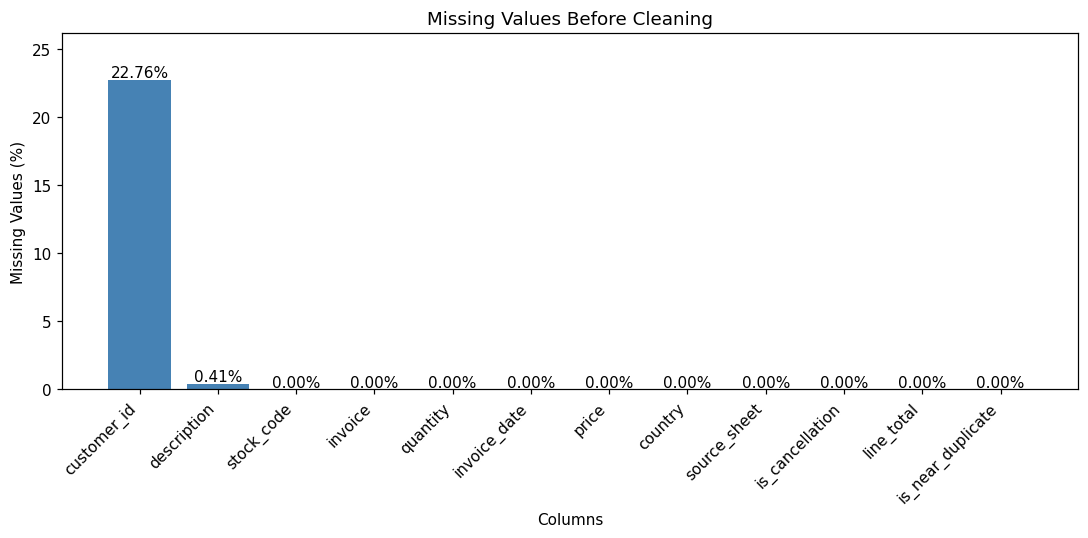

In [ ]:

# 3.4.2 Missing Value Bar Chart

missing_percent = (
    clean.isnull().mean() * 100
).sort_values(ascending=False)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    missing_percent.index,
    missing_percent.values,
    color="steelblue"
)

plt.title("Missing Values Before Cleaning")
plt.xlabel("Columns")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45, ha="right")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.2,
        f"{height:.2f}%",
        ha="center"
    )

plt.ylim(0, max(missing_percent.max() * 1.15, 1))
plt.tight_layout()
plt.show()



### 3.4.3 Handling Missing Values

Different methods are used to handle missing values based on the meaning of each column.

- **Description:** Missing descriptions are replaced with "UNKNOWN PRODUCT" because the transaction may still contain useful information. This avoids removing valid transactions.
- **Customer ID:** Missing customer IDs are kept and flagged because filling them with random or common IDs could give incorrect customer information.
- **Other important columns:** Rows with missing essential transaction fields are removed only if such missing values are found, because these fields are needed for reliable transaction analysis.



In [ ]:

# 3.4.3 Handle Missing Values

# Copy Member 1's cleaned dataset
clean_m2 = clean.copy()

# Flag missing Customer IDs
clean_m2["customer_id_missing"] = (
    clean_m2["customer_id"].isnull()
)

# Fill missing product descriptions
clean_m2["description"] = (
    clean_m2["description"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("UNKNOWN PRODUCT")
)

# Check essential transaction columns
essential_columns = [
    "invoice", "stock_code", "quantity",
    "invoice_date", "price", "country"
]

rows_before = len(clean_m2)

clean_m2 = clean_m2.dropna(
    subset=essential_columns
).copy()

rows_dropped = rows_before - len(clean_m2)

print("Rows removed due to missing essential values:", rows_dropped)
print("Missing Customer IDs retained:",
      clean_m2["customer_id"].isnull().sum())

print("\nMissing Values After Handling:")
display(clean_m2.isnull().sum().to_frame("Missing Count"))


Rows removed due to missing essential values: 0
Missing Customer IDs retained: 235151

Missing Values After Handling:


,Missing Count
invoice,0
stock_code,0
description,0
quantity,0
invoice_date,0
price,0
customer_id,235151
country,0
source_sheet,0
is_cancellation,0



### 3.4.4 Standardizing Date and Text Formats

Inconsistent formats can affect data analysis because the same information may be represented differently. We standardize product descriptions and country text by removing unnecessary spaces. We also verify that invoice dates use a consistent datetime data type.

Some text formatting was already handled by Member 1, so this step continues the existing cleaning process.


In [ ]:

# 3.4.4 Standardize Text and Date Formats

# Standardize product descriptions
clean_m2["description"] = (
    clean_m2["description"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.upper()
)

# Standardize country text
clean_m2["country"] = (
    clean_m2["country"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)
# Convert country back to category data type
clean_m2["country"] = clean_m2["country"].astype("category")

# Ensure InvoiceDate uses datetime format
clean_m2["invoice_date"] = pd.to_datetime(
    clean_m2["invoice_date"],
    errors="coerce"
)

print("Data Types After Standardization:")
display(clean_m2[
    ["description", "country", "invoice_date"]
].dtypes.to_frame("Data Type"))

print("\nSample Data After Standardization:")
display(clean_m2[
    ["description", "country", "invoice_date"]
].head(10))


Data Types After Standardization:


,Data Type
description,string[python]
country,category
invoice_date,datetime64[ns]



Sample Data After Standardization:


,description,country,invoice_date
0,15CM CHRISTMAS GLASS BALL 20 LIGHTS,United Kingdom,2009-12-01 07:45:00
1,PINK CHERRY LIGHTS,United Kingdom,2009-12-01 07:45:00
2,WHITE CHERRY LIGHTS,United Kingdom,2009-12-01 07:45:00
3,"RECORD FRAME 7"" SINGLE SIZE",United Kingdom,2009-12-01 07:45:00
4,STRAWBERRY CERAMIC TRINKET BOX,United Kingdom,2009-12-01 07:45:00
5,PINK DOUGHNUT TRINKET POT,United Kingdom,2009-12-01 07:45:00
6,SAVE THE PLANET MUG,United Kingdom,2009-12-01 07:45:00
7,FANCY FONT HOME SWEET HOME DOORMAT,United Kingdom,2009-12-01 07:45:00
8,CAT BOWL,United Kingdom,2009-12-01 07:46:00
9,"DOG BOWL , CHASING BALL DESIGN",United Kingdom,2009-12-01 07:46:00


In [ ]:

# Check text formatting changes (Before vs After)

# Compare product descriptions
description_before = clean["description"].fillna("UNKNOWN PRODUCT").astype("string")

description_after = clean_m2["description"].astype("string")

description_changed = (
    description_before.ne(description_after).fillna(False).sum()
)

# Compare country text
country_before = clean["country"].astype("string")
country_after = clean_m2["country"].astype("string")

country_changed = (
    country_before.ne(country_after).fillna(False).sum()
)

# Display results
print("Text Formatting Changes:")
print("Description values changed:", description_changed)
print("Country values changed:", country_changed)
print("Invoice Date Type:", clean_m2["invoice_date"].dtype)


Text Formatting Changes:
Description values changed: 5843
Country values changed: 0
Invoice Date Type: datetime64[ns]



### 3.4.5 Missing Values Before and After Cleaning

The table below compares missing values before and after the cleaning process. This allows us to evaluate whether the selected handling methods were effective while keeping useful transaction information.


In [ ]:

# 3.4.5 Before vs After Comparison

comparison = pd.DataFrame({
    "Before Missing": clean.isnull().sum(),
    "After Missing": clean_m2[clean.columns].isnull().sum(),
    "Before (%)": (
        clean.isnull().mean() * 100
    ).round(2),
    "After (%)": (
        clean_m2[clean.columns].isnull().mean() * 100
    ).round(2)
})

print("Missing Values: Before vs After")
display(comparison)

print("\nOriginal Rows:", len(clean))
print("Rows After Cleaning:", len(clean_m2))
print("Rows Removed:", len(clean) - len(clean_m2))


Missing Values: Before vs After


,Before Missing,After Missing,Before (%),After (%)
invoice,0,0,0.00,0.00
stock_code,0,0,0.00,0.00
description,4275,0,0.41,0.00
quantity,0,0,0.00,0.00
invoice_date,0,0,0.00,0.00
price,0,0,0.00,0.00
customer_id,235151,235151,22.76,22.76
country,0,0,0.00,0.00
source_sheet,0,0,0.00,0.00
is_cancellation,0,0,0.00,0.00



Original Rows: 1033036
Rows After Cleaning: 1033036
Rows Removed: 0



### 3.4.6 Discussion and Justification

After checking the dataset, we found that some columns contain missing values, especially customer IDs and product descriptions.

For missing product descriptions, we replaced the empty values with "UNKNOWN PRODUCT" because the other transaction information is still useful for analysis. We decided not to remove these rows to avoid losing unnecessary data.

For missing customer IDs, we kept the missing values and added a flag column. This is because customer IDs are unique identifiers, and replacing them with estimated values could lead to incorrect customer analysis.

We also checked inconsistent date and text formats. Product descriptions were standardized by removing extra spaces and converting them to uppercase. Country names were cleaned by removing unnecessary spaces, while invoice dates were converted into a consistent datetime format.

Overall, the cleaning process improved data consistency while preserving useful transaction records. However, missing customer IDs still remain and should be considered when performing customer-level analysis.


### 4. Outlier Detection and Handling

In this section, we will identify outliers and invalid values in the Online Retail II dataset. We will focus on the quantity and price columns because unusual values in these columns can affect sales analysis. We will use the IQR method to detect potential outliers and decide how to handle them based on the transaction records.

In [ ]:
#Check the data before outlier detection

# Create a copy so the original cleaned data is not changed
df_member3 = clean.copy()

# Check the dataset size
print("Dataset shape:", df_member3.shape)

# Display summary statistics for quantity and price
display(df_member3[['quantity', 'price']].describe())


Dataset shape: (1033036, 12)


,quantity,price
count,"1,033,036.00","1,033,036.00"
mean,10.08,4.61
std,175.20,122.40
min,"-80,995.00","-53,594.36"
25%,1.00,1.25
50%,3.00,2.10
75%,10.00,4.15
max,"80,995.00","38,970.00"


#### 4.1 Detecting Outliers Using IQR

We used the Interquartile Range (IQR) method to identify outliers in the quantity and price columns. The IQR method helps us detect values that are unusually high or low compared to most transactions. We will examine these outliers before deciding whether to keep or remove them, because some unusual values may still represent valid sales.

In [ ]:

# Detect outliers using the IQR method

for col in ['quantity', 'price']:
    Q1 = df_member3[col].quantile(0.25)
    Q3 = df_member3[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_member3[
        (df_member3[col] < lower_bound) |
        (df_member3[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of outliers:", len(outliers))
    print("Percentage of outliers:",
          round(len(outliers) / len(df_member3) * 100, 2), "%")



Column: quantity
Q1: 1.0
Q3: 10.0
IQR: 9.0
Lower Bound: -12.5
Upper Bound: 23.5
Number of outliers: 114434
Percentage of outliers: 11.08 %

Column: price
Q1: 1.25
Q3: 4.15
IQR: 2.9000000000000004
Lower Bound: -3.1000000000000005
Upper Bound: 8.5
Number of outliers: 66196
Percentage of outliers: 6.41 %


#### 4.2 Outlier Visualisation Using Boxplots

We created boxplots for the quantity and price columns to visualise the distribution of the data and identify potential outliers. The boxplots help us see values that are far away from most transactions. These unusual values will be examined before deciding whether they should be kept or removed.

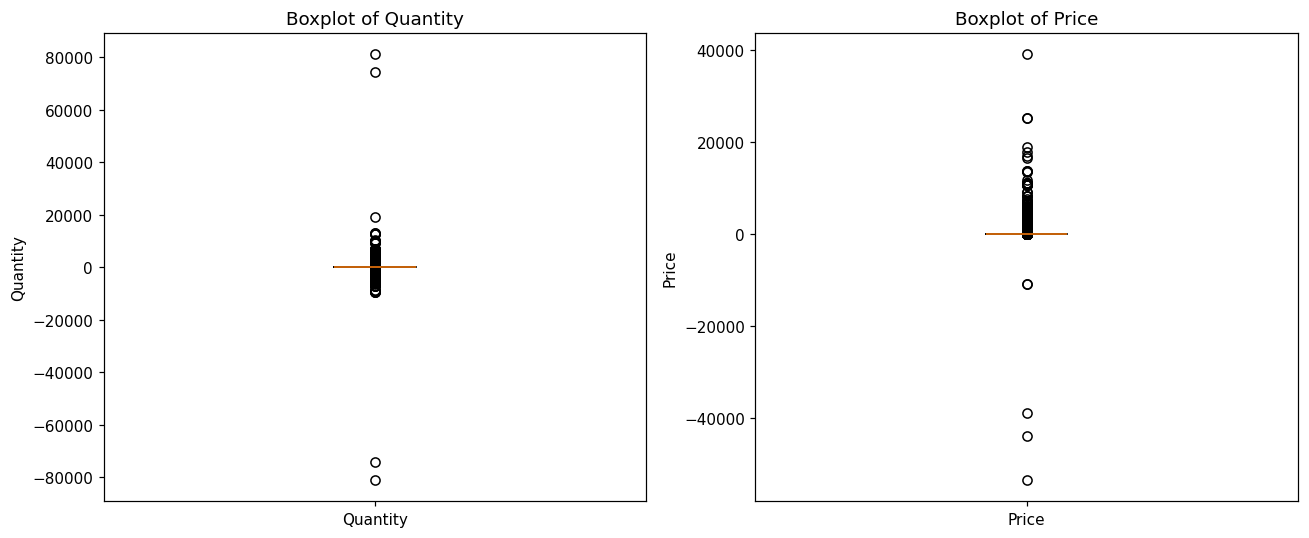

In [ ]:
import matplotlib.pyplot as plt

# Create boxplots for quantity and price
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Quantity boxplot
axes[0].boxplot(df_member3['quantity'].dropna())
axes[0].set_title('Boxplot of Quantity')
axes[0].set_ylabel('Quantity')
axes[0].set_xticks([1])
axes[0].set_xticklabels(['Quantity'])

# Price boxplot
axes[1].boxplot(df_member3['price'].dropna())
axes[1].set_title('Boxplot of Price')
axes[1].set_ylabel('Price')
axes[1].set_xticks([1])
axes[1].set_xticklabels(['Price'])

plt.tight_layout()
plt.show()


#### 4.3 Identifying Invalid Values

After detecting the outliers, we checked for negative and zero values in the quantity and price columns. Negative quantities may represent cancelled orders or returned products, while zero or negative prices may represent missing prices, adjustments or incorrect records. We need to check these values before deciding how to handle them.

In [ ]:
# Check invalid and unusual transaction values

print("--- Quantity ---")
print("Negative quantities:",
      (df_member3['quantity'] < 0).sum())

print("Zero quantities:",
      (df_member3['quantity'] == 0).sum())

print("--- Price ---")
print("Negative prices:",
      (df_member3['price'] < 0).sum())

print("Zero prices:",
      (df_member3['price'] == 0).sum())

# Display sample records with negative quantities or non-positive prices
problem_rows = df_member3[
    (df_member3['quantity'] <= 0) |
    (df_member3['price'] <= 0)
]

print("\nSample problematic records:")
display(problem_rows.head(10))


--- Quantity ---
Negative quantities: 22496
Zero quantities: 0
--- Price ---
Negative prices: 5
Zero prices: 6014

Sample problematic records:


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,source_sheet,is_cancellation,line_total,is_near_duplicate
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321,Australia,Year 2009-2010,True,-35.40,False
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321,Australia,Year 2009-2010,True,-9.90,False
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321,Australia,Year 2009-2010,True,-17.00,False
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321,Australia,Year 2009-2010,True,-12.60,False
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321,Australia,Year 2009-2010,True,-35.40,False
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321,Australia,Year 2009-2010,True,-15.00,False
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321,Australia,Year 2009-2010,True,-15.00,False
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321,Australia,Year 2009-2010,True,-20.40,False
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321,Australia,Year 2009-2010,True,-35.40,False
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592,United Kingdom,Year 2009-2010,True,-12.75,False


#### 4.4 Handling Invalid Values

Based on our results, we found 22,496 negative quantities, 5 negative prices and 6,014 zero prices. We also found that some transactions were marked as cancellations.

We decided to keep the original records because cancellation transactions may be useful for analysing returns. However, for normal sales analysis, we created a separate dataset that only includes transactions with positive quantities and prices and excludes cancelled invoices.

We did not remove all IQR outliers because some unusually large purchases may be valid transactions.

In [ ]:

# Create a dataset for normal sales analysis

# Keep the original data
df_before = df_member3.copy()

# Create a separate sales-only dataset
df_after = df_member3[
    (df_member3['quantity'] > 0) &
    (df_member3['price'] > 0) &
    (df_member3['is_cancellation'] == False)
].copy()

# Compare before and after cleaning
print("--- Before Cleaning ---")
print("Total records:", len(df_before))
print("Negative quantities:", (df_before['quantity'] < 0).sum())
print("Zero quantities:", (df_before['quantity'] == 0).sum())
print("Negative prices:", (df_before['price'] < 0).sum())
print("Zero prices:", (df_before['price'] == 0).sum())

print("\n--- After Cleaning ---")
print("Total records:", len(df_after))
print("Negative quantities:", (df_after['quantity'] < 0).sum())
print("Zero quantities:", (df_after['quantity'] == 0).sum())
print("Negative prices:", (df_after['price'] < 0).sum())
print("Zero prices:", (df_after['price'] == 0).sum())

print("\nRecords excluded from sales-only dataset:",
      len(df_before) - len(df_after))


--- Before Cleaning ---
Total records: 1033036
Negative quantities: 22496
Zero quantities: 0
Negative prices: 5
Zero prices: 6014

--- After Cleaning ---
Total records: 1007913
Negative quantities: 0
Zero quantities: 0
Negative prices: 0
Zero prices: 0

Records excluded from sales-only dataset: 25123


#### 4.5 Before and After Cleaning Comparison

After cleaning, the number of records decreased from 1,033,036 to 1,007,913. A total of 25,123 records were excluded from the sales-only dataset because they contained non-positive quantities, non-positive prices or were marked as cancellations. This represents approximately 2.43% of the original dataset.

The cleaned data no longer contains negative quantities or zero and negative prices. However, some positive outliers may still remain because they could represent genuine bulk purchases or high-value transactions.

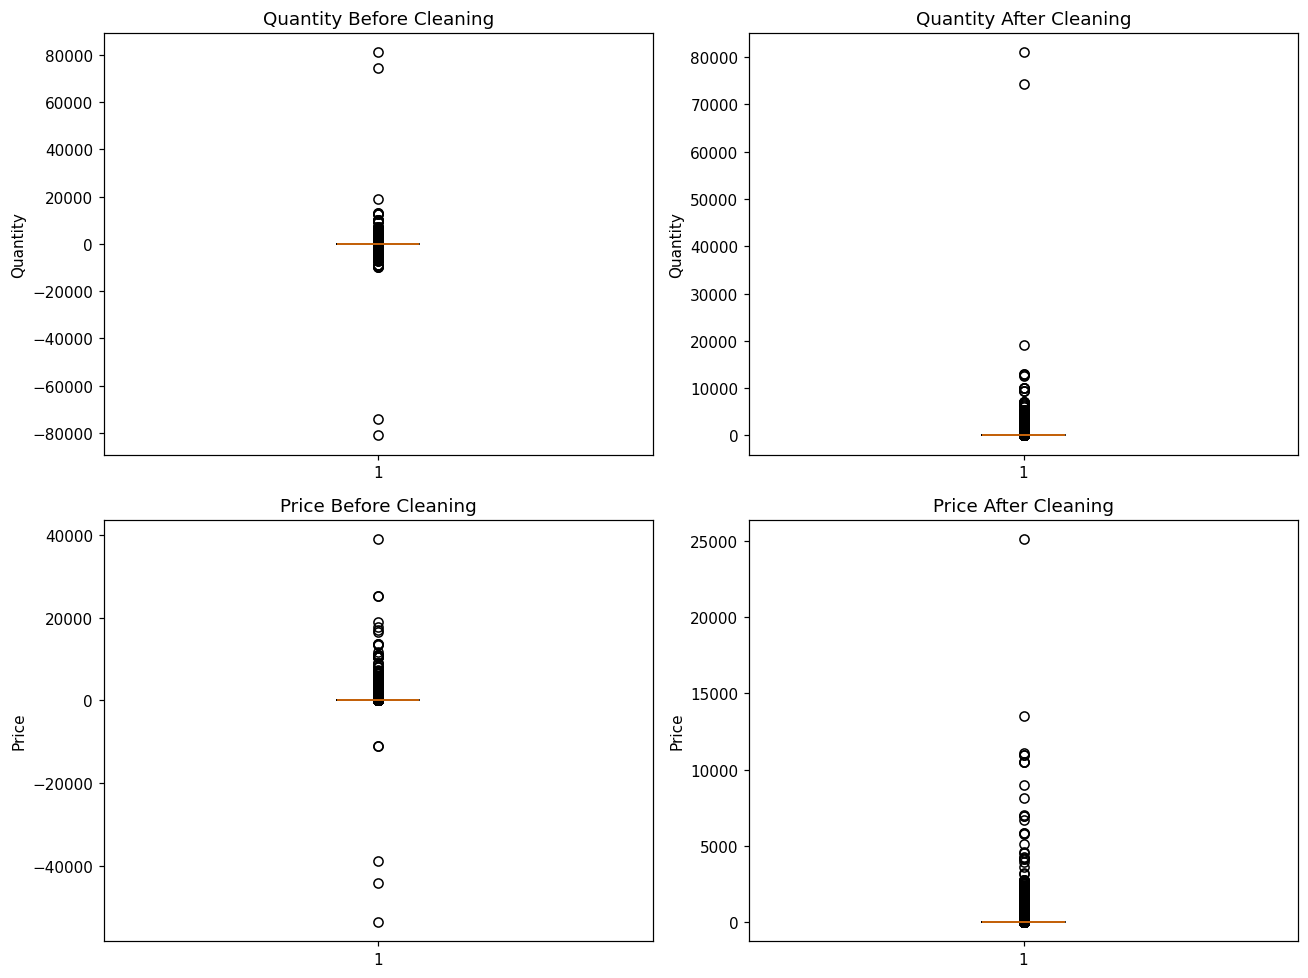

In [ ]:

import matplotlib.pyplot as plt

# Compare quantity and price before and after cleaning
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Quantity before cleaning
axes[0, 0].boxplot(df_before['quantity'].dropna())
axes[0, 0].set_title('Quantity Before Cleaning')
axes[0, 0].set_ylabel('Quantity')

# Quantity after cleaning
axes[0, 1].boxplot(df_after['quantity'].dropna())
axes[0, 1].set_title('Quantity After Cleaning')
axes[0, 1].set_ylabel('Quantity')

# Price before cleaning
axes[1, 0].boxplot(df_before['price'].dropna())
axes[1, 0].set_title('Price Before Cleaning')
axes[1, 0].set_ylabel('Price')

# Price after cleaning
axes[1, 1].boxplot(df_after['price'].dropna())
axes[1, 1].set_title('Price After Cleaning')
axes[1, 1].set_ylabel('Price')

plt.tight_layout()
plt.show()


#### 4.6 Investigating Remaining Outliers

After cleaning, some extreme positive values still remain in the quantity and price columns. These values are not necessarily errors because large quantities may represent bulk purchases. However, unusually high prices may also represent special charges or adjustments. We will examine the transaction details before deciding whether to keep these records.

In [ ]:

# Check the top 10 highest quantities
print("--- Top 10 Highest Quantities ---")

display(
    df_after.nlargest(10, 'quantity')[
        ['invoice', 'stock_code', 'description',
         'quantity', 'price', 'is_cancellation']
    ]
)

# Check the top 10 highest prices
print("\n--- Top 10 Highest Prices ---")

display(
    df_after.nlargest(10, 'price')[
        ['invoice', 'stock_code', 'description',
         'quantity', 'price', 'is_cancellation']
    ]
)


--- Top 10 Highest Quantities ---


,invoice,stock_code,description,quantity,price,is_cancellation
1031554,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,False
557400,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,False
89849,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,False
125789,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,False
125791,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,False
125792,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,False
125790,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,False
133513,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,False
133514,502269,21982,PACK OF 12 SUKI TISSUES,10000,0.25,False
133515,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,0.25,False



--- Top 10 Highest Prices ---


,invoice,stock_code,description,quantity,price,is_cancellation
238929,512771,M,Manual,1,"25,111.09",False
511151,537632,AMAZONFEE,AMAZON FEE,1,"13,541.33",False
794039,A563185,B,Adjust bad debt,1,"11,062.06",False
133499,502263,M,Manual,1,"10,953.50",False
133501,502265,M,Manual,1,"10,953.50",False
338134,522796,M,Manual,1,"10,468.80",False
354429,524159,M,Manual,1,"10,468.80",False
368451,525399,M,Manual,1,"10,468.80",False
73561,496115,M,Manual,1,"8,985.60",False
668267,551697,POST,POSTAGE,1,"8,142.75",False


#### 4.7 Handling Remaining Outliers

After checking the highest quantities and prices, we found that some large quantities were linked to actual products, such as PAPER CRAFT, LITTLE BIRDIE and MEDIUM CERAMIC TOP STORAGE JAR. We decided to keep these records because they may represent bulk purchases.

However, some high-price records were not normal product sales. For example, the dataset contains Manual, AMAZON FEE, Adjust bad debt and POSTAGE records. We decided to exclude these types of records from product-sales analysis because they represent charges or accounting adjustments rather than product purchases.

We did not use IQR capping because it could change valid transaction values and affect sales calculations.

In [ ]:

# Separate non-product charges

# Create a copy of the sales-only dataset
df_final = df_after.copy()

# Known non-product stock codes from the investigation
non_product_codes = [
    'M',           # Manual adjustment
    'AMAZONFEE',   # Amazon fee
    'B',           # Bad debt adjustment
    'POST'         # Postage
]

# Identify non-product records
non_product_mask = (
    df_final['stock_code'].astype(str).str.upper().str.strip()
    .isin(non_product_codes)
)

# Show the number of non-product records
print("Non-product records identified:", non_product_mask.sum())

# Create product-sales dataset
df_final = df_final[~non_product_mask].copy()

print("\n--- Final Comparison ---")
print("Original records:", len(df_before))
print("Sales-only records:", len(df_after))
print("Product-sales records:", len(df_final))
print("Additional records excluded:",
      len(df_after) - len(df_final))

# Verify the remaining highest prices
print("\nTop 10 prices after filtering:")
display(
    df_final.nlargest(10, 'price')[
        ['invoice', 'stock_code', 'description', 'quantity', 'price']
    ]
)


Non-product records identified: 2706

--- Final Comparison ---
Original records: 1033036
Sales-only records: 1007913
Product-sales records: 1005207
Additional records excluded: 2706

Top 10 prices after filtering:


,invoice,stock_code,description,quantity,price
70301,495798,ADJUST,Adjustment by john on 26/01/2010 17,1,"5,117.03"
791788,562955,DOT,DOTCOM POSTAGE,1,"4,505.17"
984841,578149,DOT,DOTCOM POSTAGE,1,"2,275.54"
1016181,580610,DOT,DOTCOM POSTAGE,1,"2,196.67"
1016416,580612,DOT,DOTCOM POSTAGE,1,"2,114.00"
993724,578833,DOT,DOTCOM POSTAGE,1,"2,028.25"
924121,573585,DOT,DOTCOM POSTAGE,1,"2,019.05"
1024689,581023,DOT,DOTCOM POSTAGE,1,"1,861.46"
1032673,581498,DOT,DOTCOM POSTAGE,1,"1,714.17"
1028416,581238,DOT,DOTCOM POSTAGE,1,"1,683.75"


#### 4.8 Final Outlier Cleaning and Verification

After removing the first group of non-product records, we found that some adjustment and postage transactions still remained. These records used stock codes such as ADJUST and DOT. We decided to exclude these records from product-sales analysis because they do not represent actual products sold to customers.

We kept the original transaction data separately and continued to retain unusually high product quantities, since they could represent genuine bulk purchases.

In [ ]:

# Update the non-product code list

non_product_codes = [
    'M',
    'AMAZONFEE',
    'B',
    'POST',
    'ADJUST',
    'DOT'
]

# Start again from the sales-only dataset
df_final = df_after.copy()

# Find non-product records
non_product_mask = (
    df_final['stock_code']
    .astype(str)
    .str.upper()
    .str.strip()
    .isin(non_product_codes)
)

# Exclude non-product records
df_final = df_final[~non_product_mask].copy()

# Final comparison
print("--- Final Data Cleaning Summary ---")
print("Original records:", len(df_before))
print("Sales-only records:", len(df_after))
print("Final product-sales records:", len(df_final))
print("Non-product records excluded:",
      non_product_mask.sum())
print("Total records excluded:",
      len(df_before) - len(df_final))

# Check invalid values
print("\n--- Final Invalid Value Check ---")
print("Negative quantities:", (df_final['quantity'] < 0).sum())
print("Zero quantities:", (df_final['quantity'] == 0).sum())
print("Negative prices:", (df_final['price'] < 0).sum())
print("Zero prices:", (df_final['price'] == 0).sum())

# Display highest remaining prices
print("\nTop 10 highest remaining prices:")
display(
    df_final.nlargest(10, 'price')[
        ['invoice', 'stock_code', 'description',
         'quantity', 'price']
    ]
)


--- Final Data Cleaning Summary ---
Original records: 1033036
Sales-only records: 1007913
Final product-sales records: 1003756
Non-product records excluded: 4157
Total records excluded: 29280

--- Final Invalid Value Check ---
Negative quantities: 0
Zero quantities: 0
Negative prices: 0
Zero prices: 0

Top 10 highest remaining prices:


,invoice,stock_code,description,quantity,price
189991,507637,84016,FLAG OF ST GEORGE CAR FLAG,1,"1,157.15"
134868,502451,84016,FLAG OF ST GEORGE CAR FLAG,1,867.79
717210,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50
717221,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,649.50
178910,506571,84016,FLAG OF ST GEORGE CAR FLAG,1,408.40
246714,513566,ADJUST2,Adjustment by Peter on Jun 25 2010,1,358.47
246713,513564,ADJUST2,Adjustment by Peter on Jun 25 2010,1,300.13
265384,515349,22656,VINTAGE BLUE KITCHEN CABINET,1,295.00
265385,515349,22655,VINTAGE RED KITCHEN CABINET,1,295.00
265625,515403,22655,VINTAGE RED KITCHEN CABINET,1,295.00


#### 4.9 Final Data Verification

During the final inspection, we found another accounting adjustment with the stock code ADJUST2. We decided to exclude this record type from product-sales analysis because it does not represent an actual product purchase.

After filtering the known non-product transactions, we will compare the remaining outliers using the IQR method. We will keep potential bulk purchases rather than automatically removing them, since unusually large quantities do not always indicate incorrect data.

In [ ]:

# Remove the remaining known adjustment code

df_final = df_final[
    df_final['stock_code'].astype(str).str.upper().str.strip()
    != 'ADJUST2'
].copy()

# Function to count IQR outliers
def count_iqr_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return (
        (data[column] < lower) |
        (data[column] > upper)
    ).sum()

# Compare outlier counts
import pandas as pd

comparison = pd.DataFrame({
    'Column': ['quantity', 'price'],
    'Outliers Before': [
        count_iqr_outliers(df_before, 'quantity'),
        count_iqr_outliers(df_before, 'price')
    ],
    'Outliers After': [
        count_iqr_outliers(df_final, 'quantity'),
        count_iqr_outliers(df_final, 'price')
    ]
})

print("--- IQR Outlier Comparison ---")
display(comparison)

print("\nFinal records:", len(df_final))
print("Total records excluded:", len(df_before) - len(df_final))

print("\nHighest remaining prices:")
display(
    df_final.nlargest(10, 'price')[
        ['stock_code', 'description', 'quantity', 'price']
    ]
)


--- IQR Outlier Comparison ---


,Column,Outliers Before,Outliers After
0,quantity,114434,53020
1,price,66196,75440



Final records: 1003753
Total records excluded: 29283

Highest remaining prices:


,stock_code,description,quantity,price
189991,84016,FLAG OF ST GEORGE CAR FLAG,1,"1,157.15"
134868,84016,FLAG OF ST GEORGE CAR FLAG,1,867.79
717210,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50
717221,22502,PICNIC BASKET WICKER 60 PIECES,1,649.50
178910,84016,FLAG OF ST GEORGE CAR FLAG,1,408.40
265384,22656,VINTAGE BLUE KITCHEN CABINET,1,295.00
265385,22655,VINTAGE RED KITCHEN CABINET,1,295.00
265625,22655,VINTAGE RED KITCHEN CABINET,1,295.00
267389,22656,VINTAGE BLUE KITCHEN CABINET,1,295.00
269044,22656,VINTAGE BLUE KITCHEN CABINET,1,295.00


#### 5. Summary of Outlier and Invalid Value Handling

We used the IQR method and boxplots to detect outliers in the quantity and price columns. Before cleaning, we found 114,434 quantity outliers and 66,196 price outliers.

After checking the transaction details, we decided to exclude cancellation records, non-positive quantities and prices, and identifiable non-product charges such as Manual, AMAZON FEE, POSTAGE and adjustment records.

The dataset was reduced from 1,033,036 to 1,003,753 records. The number of quantity outliers decreased to 53,020, while price outliers increased to 75,440 because the IQR boundaries changed after cleaning.

We kept the remaining positive outliers because they may represent genuine bulk purchases or expensive products. Removing these values without proper checking could affect the accuracy of the sales analysis.

Overall, the cleaned dataset is more suitable for analysing product sales, although some unusual transactions may still require further investigation.

In [ ]:

# Final verification

print("=== MEMBER 3 FINAL SUMMARY ===")

print("Original records:", len(df_before))
print("Final records:", len(df_final))
print("Records excluded:", len(df_before) - len(df_final))

print("\nInvalid values remaining:")
print("Negative quantity:", (df_final['quantity'] < 0).sum())
print("Zero quantity:", (df_final['quantity'] == 0).sum())
print("Negative price:", (df_final['price'] < 0).sum())
print("Zero price:", (df_final['price'] == 0).sum())

print("\nIQR outlier comparison:")
display(comparison)

# Save final cleaned dataset for the next group member
df_member3_cleaned = df_final.copy()

print("\nMember 3 cleaned dataset is ready.")


=== MEMBER 3 FINAL SUMMARY ===
Original records: 1033036
Final records: 1003753
Records excluded: 29283

Invalid values remaining:
Negative quantity: 0
Zero quantity: 0
Negative price: 0
Zero price: 0

IQR outlier comparison:


,Column,Outliers Before,Outliers After
0,quantity,114434,53020
1,price,66196,75440



Member 3 cleaned dataset is ready.
